# Planet-moon injection and retrieval

Steps in this tutorial:
1. Create a planet+moon model at Kepler long cadence (30 min) and add Gaussian noise
2. Fit it with Pandora's nested sampler: planet+moon **and** planet-only, with the same priors
3. Compare the Bayesian evidences (the Bayes factor)
4. Look at the posteriors (corner plot)
5. Plot the maximum-likelihood light curves of both models

The fit uses `pandoramoon.NestedSampler`, a compiled nested sampler built for Pandora's fast likelihood. It
runs on all cores, checks its own convergence and samples the moon's orbit in coordinates that avoid the
period aliases of moons seen only during transits. Details: the documentation page *Fitting* (`docs/Fitting.rst`).

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [12, 8]
import numpy as np

import pandoramoon as pandora
from pandoramoon import NestedSampler, Uniform

## Create planet+moon model

Star and limb darkening:

In [2]:
params = pandora.model_params()
R_sun = 696_342_000
params.R_star = R_sun  # [m]
params.u1 = 0.4089
params.u2 = 0.2556

Planet parameters:

In [3]:
params.per_bary = 365.25  # [days]
params.a_bary = 215  # [R_star]
params.r_planet = 0.1 # [R_star]
params.b_bary = 0.3   # [0..1]
params.t0_bary = 11  # [days]
params.t0_bary_offset = 0.01  # [days]
params.M_planet = 1.8986e+27  # [kg]
params.w_bary = 0  # [deg]
params.ecc_bary = 0.0  # [0..1]

Moon parameters (an Earth-sized moon on a 5-day orbit):

In [4]:
params.r_moon = 0.03526 # [R_star]
params.per_moon = 5 # [days]
params.tau_moon = 0.07  # [0..1]
params.Omega_moon = 0  # [0..180]
params.i_moon = 90  # [0..180]
params.ecc_moon = 0  # [0..1]
params.w_moon = 0  # [deg]
params.M_moon = 0.05395 * params.M_planet   # [kg]

Other model parameters, e.g. 30 min Kepler cadence:

In [5]:
params.epochs = 3  # [int]
params.epoch_duration = 2  # [days]
params.cadences_per_day = 48  # [int]
params.epoch_distance = 365.26   # [days]
params.supersampling_factor = 1  # [int]
params.occult_small_threshold = 0  # 0: exact moon occultation
params.hill_sphere_threshold = 1.0  # the same value as in the fit below

Time grid, model and light curve:

In [6]:
time = pandora.time(params).grid()
model = pandora.moon_model(params)
injected_flux_total, injected_flux_planet, injected_flux_moon = model.light_curve(time)

## Create noise and merge with flux

In [7]:
noise_level = 500e-6  # Gaussian noise to be added to the generated data
np.random.seed(0)  # Reproducibility
noise = np.random.normal(0, noise_level, len(time))
testdata = noise + injected_flux_total
yerr = np.full(len(testdata), noise_level)

The three transits, with the planet (blue), moon (red) and total (black) flux:

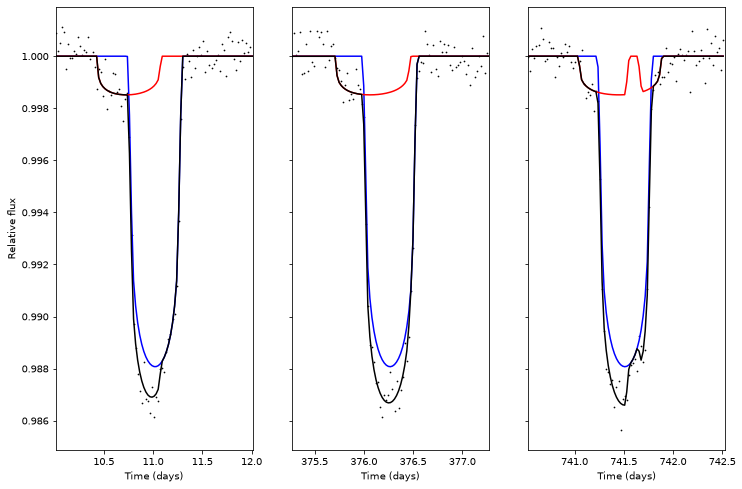

In [8]:
fig, axs = plt.subplots(1, 3, sharey=True)
for k, ax in enumerate(axs):
    ax.plot(time, injected_flux_planet, color="blue")
    ax.plot(time, injected_flux_moon, color="red")
    ax.plot(time, injected_flux_total, color="black")
    ax.scatter(time, testdata, color="black", s=0.5)
    ax.set_xlim(min(time) + k * params.epoch_distance, min(time) + params.epoch_duration + k * params.epoch_distance)
    ax.set_xlabel("Time (days)")
axs[0].set_ylabel("Relative flux")
plt.show()

Interestingly, transit 3 of 3 has a planet-moon occultation!

## Fit with Pandora's nested sampler

The data go into a `Likelihood` object. It precomputes the data terms once and evaluates the model only
near transit. Its settings (supersampling, Hill-sphere threshold, ...) are used by the fit.

In [9]:
like = pandora.Likelihood(
    time, testdata, yerr,
    epoch_distance=params.epoch_distance,
    supersampling_factor=1,
    occult_small_threshold=0.0,
    hill_sphere_threshold=1.0,
)

Priors: for every parameter of Pandora's model, either a prior (`Uniform`, `LogUniform`, `Normal`) or a
fixed number. Names and units are those of Pandora. The limb darkening is sampled as Kipping's `q1, q2`
(uniform in `q1, q2` = uniform over all physical quadratic laws). `t0_bary` is fixed; its uncertainty is
in `t0_bary_offset`. `w_bary`, `ecc_bary`, `ecc_moon`, `w_moon` default to 0 (circular orbits).

These are fairly wide priors around the injected values. Priors need careful consideration in a real
search: the Bayes factor depends on them.

In [10]:
priors = dict(
    q1=Uniform(0, 1), q2=Uniform(0, 1),
    R_star=Uniform(0.4 * R_sun, 1.2 * R_sun),   # [m]
    per_bary=Uniform(360.25, 370.25),           # [days]
    a_bary=Uniform(210, 220),                   # [R_star]
    r_planet=Uniform(0.07, 0.11),               # [R_star]
    b_bary=Uniform(0, 1),
    t0_bary=11,                                 # fixed [days]
    t0_bary_offset=Uniform(-0.05, 0.05),        # [days]
    M_planet=Uniform(1.5e27, 2.5e27),           # [kg]
    r_moon=Uniform(0.01, 0.07),                 # [R_star]
    per_moon=Uniform(0, 50),                    # [days]
    tau_moon=Uniform(0, 1),
    Omega_moon=Uniform(0, 180),                 # [deg]
    i_moon=Uniform(0, 180),                     # [deg]
    M_moon=Uniform(1, 1e27),                    # [kg]
)

One sampler fits both models: first planet-only (the moon parameters, and `R_star` and `M_planet`, which
act only through the moon's orbit, drop out), then planet+moon. Both use the same priors for the shared
parameters, as a Bayes factor requires. Results and files (`log_dir`) are laid out as in UltraNest.

On a 16-core machine the planet-only fit takes a few seconds and the planet+moon fit 2–4 minutes; the first
call also compiles the code (~15 s). By default all cores are used (`threads=` to change it). If the run is
interrupted, run the cell again with `resume="resume"`: the finished parts are reused.

In [11]:
sampler = NestedSampler(like, priors, log_dir="results_injection_retrieval", resume="overwrite", verbose=False)
results = sampler.run()

The summary of both fits and the Bayes factor:

In [12]:
sampler.print_results()

planet + moon: logZ = -186.036 +- 0.062   (checks passed; 38 runs x 1000 live, nsteps 64, 973 M calls, 222 s)
    q1              : 0.593572 -0.211 +0.228   (mean 0.598034, sd 0.2)
    q2              : 0.157783 -0.0767 +0.125   (mean 0.183017, sd 0.117)
    R_star          : 6.93348e+08 -8.4e+07 +6.81e+07   (mean 6.85451e+08, sd 7.64e+07)
    per_bary        : 365.253 -0.00543 +0.00599   (mean 365.254, sd 0.0053)
    a_bary          : 214.785 -3.25 +3.42   (mean 214.848, sd 2.84)
    r_planet        : 0.0995563 -0.00118 +0.00142   (mean 0.0996571, sd 0.00126)
    b_bary          : 0.208271 -0.133 +0.106   (mean 0.200493, sd 0.105)
    t0_bary_offset  : 0.00133173 -0.0145 +0.0132   (mean 0.00053593, sd 0.0128)
    M_planet        : 2.07074e+27 -3.63e+26 +3e+26   (mean 2.0481e+27, sd 2.83e+26)
    r_moon          : 0.0351021 -0.00114 +0.00114   (mean 0.0351036, sd 0.00114)
    per_moon        : 7.60458 -1.42 +2.82   (mean 8.34106, sd 2.88)
    tau_moon        : 0.516651 -0.368 +0.343   

`passed` (here: "checks passed") means the sampler's convergence checks were met: the evidence error is
≤ 0.1, the posterior is reproducible between independent halves of the runs, and doubling the chain length
would not change the result. The evidences and the Bayes factor are also in the results dictionary:

In [13]:
print("planet+moon  logZ = %.2f +- %.2f" % (results["logz"], results["logzerr"]))
print("planet only  logZ = %.2f +- %.2f" % (results["planet"]["logz"], results["planet"]["logzerr"]))
print("Bayes factor dlogZ = %.2f +- %.2f" % (results["dlogz"], results["dlogzerr"]))

planet+moon  logZ = -186.04 +- 0.06
planet only  logZ = -317.65 +- 0.04
Bayes factor dlogZ = 131.62 +- 0.08


A difference of more than ~5 in log-evidence is strong evidence (Kass & Raftery 1995). This one is
decisive for the planet+moon model.

The same numbers are saved to disk, so they can be read later without repeating the fit:

In [14]:
import json
with open("results_injection_retrieval/info/results.json") as f:
    saved = json.load(f)
with open("results_injection_retrieval/planet/info/results.json") as f:
    saved_planet = json.load(f)
print("logZ planet+moon:", saved["logz"], " planet only:", saved_planet["logz"])

logZ planet+moon: -186.03634912660576  planet only: -317.6517628186821


## Posteriors

A corner plot of the planet+moon posterior (needs the `corner` package; also saved to
`results_injection_retrieval/plots/corner.pdf`). The moon's period and phase were sampled internally in
phase-at-transit coordinates; all samples are reported in Pandora's parameters.

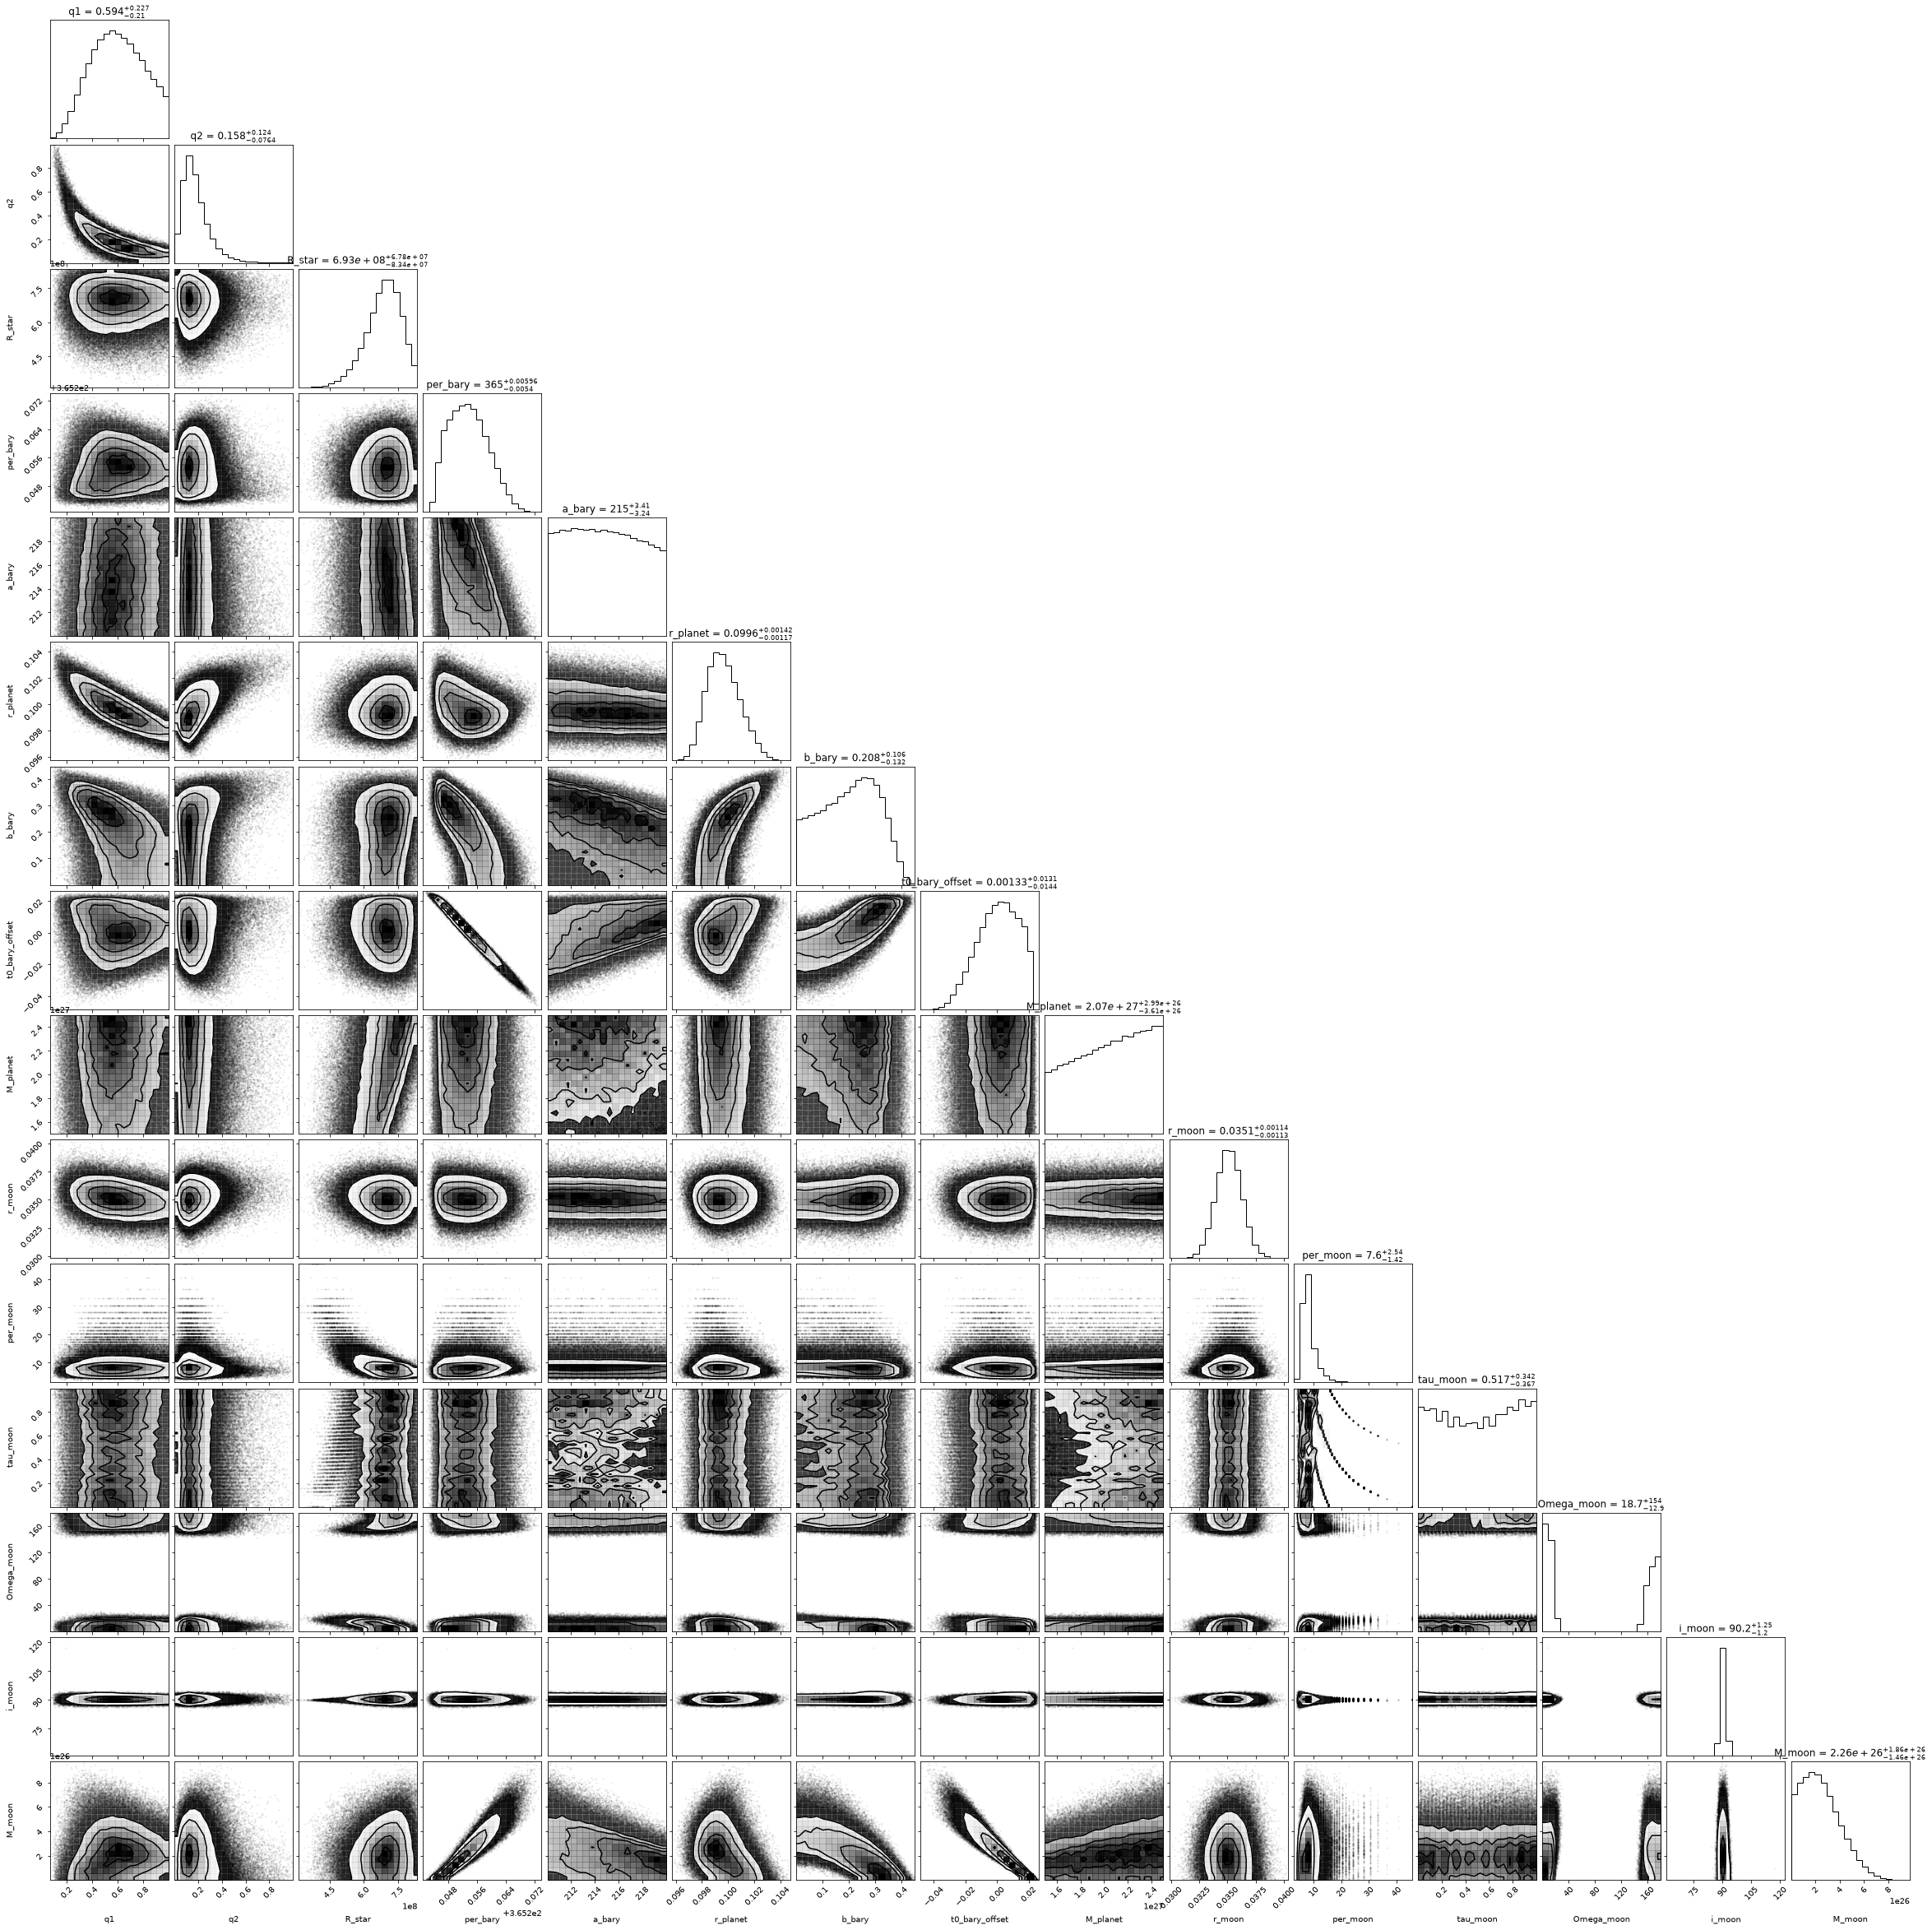

In [15]:
fig = sampler.plot_corner()
plt.show()

Median and 68 % interval of each parameter, next to the injected value:

In [16]:
injected = dict(q1=(params.u1 + params.u2) ** 2, q2=params.u1 / (2 * (params.u1 + params.u2)), R_star=params.R_star,
                per_bary=params.per_bary, a_bary=params.a_bary, r_planet=params.r_planet, b_bary=params.b_bary,
                t0_bary_offset=params.t0_bary_offset, M_planet=params.M_planet, r_moon=params.r_moon,
                per_moon=params.per_moon, tau_moon=params.tau_moon, Omega_moon=params.Omega_moon,
                i_moon=params.i_moon, M_moon=params.M_moon)
post = results["posterior"]
for j, name in enumerate(results["paramnames"]):
    print("%-15s %12.6g  [%12.6g, %12.6g]   injected %12.6g" % (
        name, post["median"][j], post["errlo"][j], post["errup"][j], injected[name]))

q1                  0.593572  [     0.38282,     0.821981]   injected      0.44156
q2                  0.157783  [   0.0811136,     0.282889]   injected     0.307675
R_star           6.93348e+08  [ 6.09385e+08,  7.61495e+08]   injected  6.96342e+08
per_bary             365.253  [     365.248,      365.259]   injected       365.25
a_bary               214.785  [     211.536,      218.208]   injected          215
r_planet           0.0995563  [    0.098376,     0.100981]   injected          0.1
b_bary              0.208271  [   0.0755734,     0.314556]   injected          0.3
t0_bary_offset    0.00133173  [  -0.0131847,    0.0145053]   injected         0.01
M_planet         2.07074e+27  [ 1.70802e+27,  2.37112e+27]   injected   1.8986e+27
r_moon             0.0351021  [   0.0339623,    0.0362429]   injected      0.03526
per_moon             7.60458  [     6.18652,       10.427]   injected            5
tau_moon            0.516651  [    0.148695,     0.859538]   injected         0.07
Omeg

The moon's radius, its inclination and the planet's parameters are recovered well. The moon's period, phase
and node are not: three transits sample the moon's orbit only three times, so many orbital periods fit
equally well (period aliases). The period posterior spreads over such aliases (here mostly 6–10 d, with the
injected 5 d in its lower tail). More transits narrow it down.

## Maximum-likelihood light curves

`sampler.parameters()` returns all Pandora parameters of the maximum-likelihood point (or of any other
point), ready for a model. First the planet-only fit:

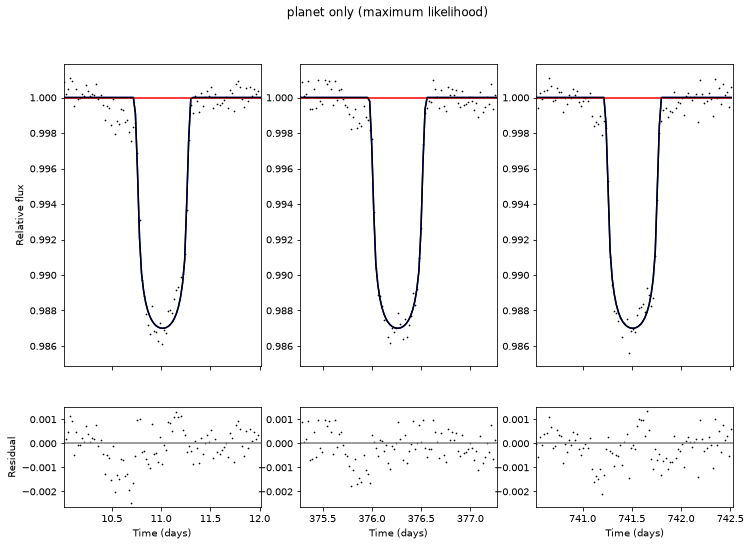

In [17]:
def model_flux(values):
    p = pandora.model_params()
    for k in ("epochs", "epoch_duration", "cadences_per_day", "epoch_distance", "supersampling_factor",
              "occult_small_threshold", "hill_sphere_threshold"):
        setattr(p, k, getattr(params, k))
    for k, v in values.items():
        setattr(p, k, v)
    return pandora.moon_model(p).light_curve(time)

po_flux_total, po_flux_planet, po_flux_moon = model_flux(sampler.parameters(model="planet"))
pm_flux_total, pm_flux_planet, pm_flux_moon = model_flux(sampler.parameters())

def plot_fit(flux_total, flux_planet, flux_moon, title):
    fig, axs = plt.subplots(2, 3, sharex="col", gridspec_kw=dict(height_ratios=[3, 1]))
    for k in range(3):
        lo = min(time) + k * params.epoch_distance
        axs[0, k].plot(time, flux_planet, color="blue")
        axs[0, k].plot(time, flux_moon, color="red")
        axs[0, k].plot(time, flux_total, color="black")
        axs[0, k].scatter(time, testdata, color="black", s=0.5)
        axs[1, k].scatter(time, testdata - flux_total, color="black", s=0.5)
        axs[1, k].axhline(0, color="grey")
        axs[1, k].set_xlim(lo, lo + params.epoch_duration)
        axs[1, k].set_xlabel("Time (days)")
    axs[0, 0].set_ylabel("Relative flux")
    axs[1, 0].set_ylabel("Residual")
    fig.suptitle(title)
    plt.show()

plot_fit(po_flux_total, po_flux_planet, po_flux_moon, "planet only (maximum likelihood)")

The planet-only fit leaves residuals around the transits, although the noise is pure white noise.
Perhaps that is the moon signal? The planet+moon fit:

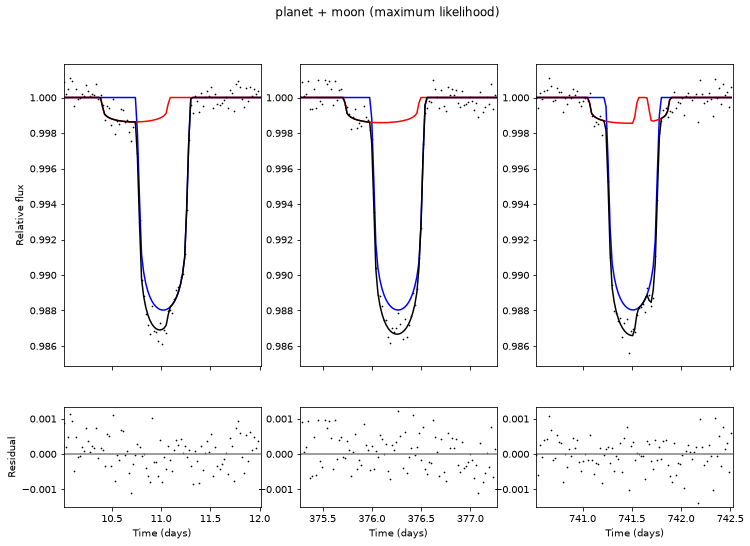

In [18]:
plot_fit(pm_flux_total, pm_flux_planet, pm_flux_moon, "planet + moon (maximum likelihood)")

The residuals are now consistent with the noise, and the maximum-likelihood model is very similar (although
not identical) to the injected one: a successful recovery.

Next steps: informative priors (e.g. `u1=Normal(0.41, 0.05)` with `ld_correlation`), `accuracy="medium"`
for faster, less precise fits, and `model="planet"` for planet-only fits. See the *Fitting* documentation.